In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import multivariate_normal
from mpl_toolkits.mplot3d import Axes3D
import random
from random import random
import pandas as pd
!pip install seaborn
import seaborn as sns
!pip install studenttmixture
from studenttmixture import EMStudentMixture
from scipy.stats import laplace

Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable


In [2]:
plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 16,
    "axes.labelsize": 14,
    "legend.fontsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12
})

In [3]:
from sklearn.cluster import KMeans
from sklearn import metrics
from sklearn.metrics import adjusted_rand_score
from scipy.spatial.distance import cdist
from sklearn.mixture import GaussianMixture

In [4]:
from scipy.stats import multivariate_normal

def generate_inliers(num_inliers, angle, sed, df=6, separation=6.5):
    np.random.seed(sed)

    n_clusters = 5

    # Unequal cluster sizes
    proportions = [0.3, 0.22, 0.18, 0.18, 0.12]
    points_per_cluster = [int(p * num_inliers) for p in proportions]

    # Centers aligned along x-axis with MORE separation
    x_centers = np.linspace(-separation, separation, n_clusters)
    mean_vectors = np.column_stack([x_centers, np.zeros(n_clusters)])
    #print(mean_vectors)
    # Leaf shape (long axis >> short axis)
    major_var = 3.0
    minor_var = 0.25

    # SAME rotation for all leaves  ///// 
    theta = angle * np.pi / 180

    R = np.array([
        [np.cos(theta), -np.sin(theta)],
        [np.sin(theta),  np.cos(theta)]
    ])

    # Shared covariance (shape only)
    Lambda = np.diag([minor_var, major_var])
    Sigma = R @ Lambda @ R.T
    L = np.linalg.cholesky(Sigma)

    X_clusters, y_clusters = [], []

    for i in range(n_clusters):
        n_i = points_per_cluster[i]

        # Z ~ N(0, Sigma)
        Z = np.random.randn(n_i, 2) @ L.T

        # U ~ chi^2(df)
        U = np.random.chisquare(df, size=n_i)

        # Multivariate Student-t inliers
        Xc = mean_vectors[i] + Z / np.sqrt(U[:, None] / df)

        y = np.full(n_i, i)
        X_clusters.append(Xc)
        y_clusters.append(y)

    return np.vstack(X_clusters), np.concatenate(y_clusters)

def generate_outlier_pool(max_outliers, sed, loc = 5, scale = 15):
    np.random.seed(sed)
    return laplace.rvs(loc = loc, scale = scale, size = (max_outliers, 2), random_state = sed)

def add_outliers_sequential(X_base, y_base, outlier_pool, frac_target):
    n_inliers = np.sum(y_base != -1)
    n_out_curr = np.sum(y_base == -1)

    # Total outliers needed for this fraction
    n_out_needed = int(frac_target * n_inliers / (1 - frac_target))
    n_new_out = n_out_needed - n_out_curr
    if n_new_out <= 0:
        return X_base, y_base

    X_new_out = outlier_pool[n_out_curr:n_out_curr + n_new_out]
    y_new_out = np.full(n_new_out, -1)

    X = np.vstack([X_base, X_new_out])
    y = np.hstack([y_base, y_new_out])

    perm = np.random.permutation(len(X))
    return X[perm], y[perm]

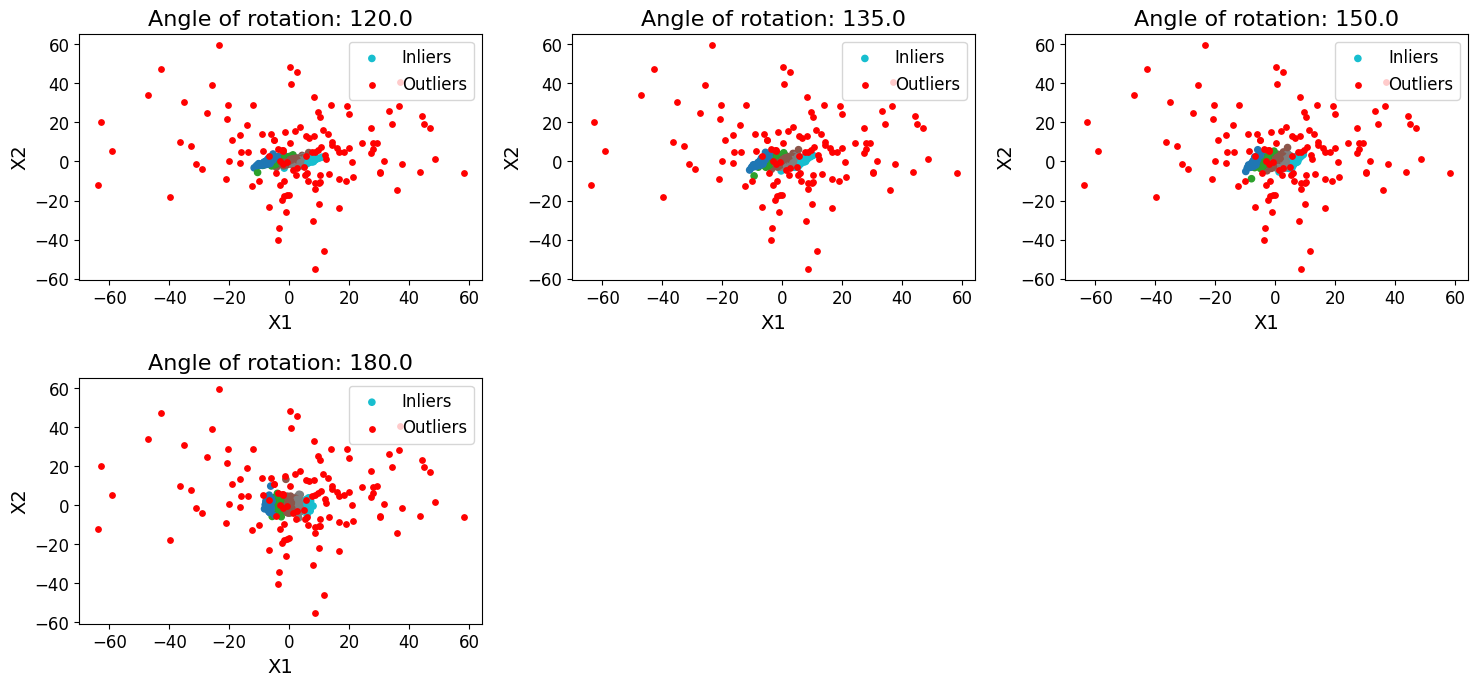

In [5]:
# Parameters
num_inliers = 500
outlier_pool_size =1000
#fractions = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5]
angles = np.array([120, 135, 150, 180])

seed = 42

# Step 1: Generate inliers


# Step 4: Plot sequentially with dynamic ranges
plt.figure(figsize=(15, 10))
#for i, frac in enumerate(fractions):
for i, angle in enumerate(angles):

    X_inliers, y_inliers = generate_inliers(num_inliers=num_inliers,angle = angle, sed=seed)

    # Step 2: Generate outlier pool
    outlier_pool = generate_outlier_pool(sed=seed, max_outliers=outlier_pool_size)

   # Step 3: Start with inliers only
    X_base, y_base = X_inliers, y_inliers
    X1, y1 = add_outliers_sequential(X_base, y_base, outlier_pool, 0.2)
    
    plt.subplot(3, 3, i+1)
    
    # Plot inliers colored by true label
    plt.scatter(X1[y1!=-1,0], X1[y1!=-1,1], c=y1[y1!=-1], cmap='tab10', s=20, label='Inliers')
    # Plot outliers
    plt.scatter(X1[y1==-1,0], X1[y1==-1,1], c='red', s=15, label='Outliers')
    plt.title(f"Angle of rotation: {angle:.1f}")

    #plt.title(f"Fraction of outliers: {frac:.1f}")
    plt.xlabel('X1')
    plt.ylabel('X2')
    plt.legend(loc='upper right')
    
    # Update base for next fraction
    #X_base, y_base = X1, y1

plt.tight_layout()
plt.show()

In [6]:
#PAM

In [7]:
!pip install scikit-learn-extra

from sklearn_extra.cluster import KMedoids

def pam(X_dat, y_dat, k, max_iter= 100):

    #start_time = time.time()
    kmedoids = KMedoids(n_clusters = k, metric = "manhattan", method = "pam", init = "random",max_iter = 100)
    #end_time = time.time()
    kmedoids.fit(X_dat)
    labels = kmedoids.labels_
    
    #diff_time = end_time-start_time
    non_outlier_indices = np.where(y_dat != -1)[0]
    #est_clust_wo_outliers = labels[non_outlier_indices]
    ari = metrics.adjusted_rand_score(labels[non_outlier_indices], y_dat[non_outlier_indices])#return labels, medoids
    return ari

Defaulting to user installation because normal site-packages is not writeable


In [8]:
#MM

In [9]:
#euclidean distance
def euclid_distance(p1, p2):
    return np.sqrt(np.sum((p1-p2)**2))

#functions for cluster assignment and cluster mean update
def assign_clusters(X_dat, clusters):
    n = X_dat.shape[0]
    for k in clusters:
        clusters[k]["points"] = []  # Clear points each iteration (moved here)

    for i in range(n):
        curr_X = X_dat[i, :]
        dist = [euclid_distance(curr_X, clusters[k]["center"]) for k in clusters]
        curr_cluster = np.argmin(dist)
        clusters[curr_cluster]["points"].append(i)  # Store index instead of point
    return clusters

def update_clusters(X_dat, clusters):
    for k in clusters:
        indices = clusters[k]["points"]
        if indices:  # Check non-empty
            cluster_members = X_dat[indices]  # Get points by index
            updated_center = cluster_members.mean(axis=0)
            clusters[k]["center"] = updated_center
    return clusters

In [10]:
#k- mean style initializations for mean and covariance
def initialization_heur(X_dat, sed):

    n, d = X_dat.shape
    np.random.seed(sed) 
    indices = np.random.choice(n, 5, replace=False)
    centroids = X_dat[indices, :]
    c1 =  X_dat[indices, :]

    clusters = {0: {"center":c1[0,:], "points":[]},
                1: {"center":c1[1,:], "points":[]},
                2: {"center":c1[2,:], "points":[]},
                3: {"center":c1[3,:], "points":[]},
                4: {"center":c1[4,:], "points":[]}
                }

    clusters = assign_clusters(X_dat, clusters)
    clusters = update_clusters(X_dat, clusters)

    cov_initial1 = np.zeros((d, d))

    for i in clusters[0]["points"]:
        diff =  (X_dat[i] - clusters[0]["center"]).reshape((d, 1))
        cov_initial1+= (diff @ diff.T)/ len(clusters[0]["points"])

    cov_initial2 = np.zeros((d, d))
    for i in clusters[1]["points"]:
        diff =  (X_dat[i] - clusters[1]["center"]).reshape((d, 1))
        cov_initial2+= (diff @ diff.T)/ len(clusters[1]["points"])

    cov_initial3 = np.zeros((d, d))
    for i in clusters[2]["points"]:
        diff =  (X_dat[i] - clusters[2]["center"]).reshape((d, 1))
        cov_initial3+= (diff @ diff.T)/ len(clusters[2]["points"])

    cov_initial4 = np.zeros((d, d))
    for i in clusters[3]["points"]:
        diff =  (X_dat[i] - clusters[3]["center"]).reshape((d, 1))
        cov_initial4+= (diff @ diff.T)/ len(clusters[3]["points"])

    cov_initial5 = np.zeros((d, d))
    for i in clusters[4]["points"]:
        diff =  (X_dat[i] - clusters[4]["center"]).reshape((d, 1))
        cov_initial5 += (diff @ diff.T)/ len(clusters[4]["points"])
    covar = [cov_initial1, cov_initial2, cov_initial3, cov_initial4, cov_initial5]
    return centroids, covar
    

In [11]:
def MM(X_dat, y_dat, sed,K=5, max_inner_iter=100, tol=1e-4):

    n, d = X_dat.shape

    # ensure float64
    X_dat = X_dat.astype(np.float64)
    # Initialization
    centroids, cov = initialization_heur(X_dat, sed)
    centroids = centroids.astype(np.float64)
    Omega = [np.linalg.inv(c.astype(np.float64)+1e-6*np.eye(d)) for c in cov]

    prev_centroids = centroids.copy()
    est_clust_assignments = np.zeros(n, dtype=int)

    for m in range(max_inner_iter):

            #  Assignment
            for i in range(n):
                dist = []

                for j in range(K):
                    const_term = ((1 / 2) ** d) * (1 / np.pi ** (d / 2)) \
                                 * (np.linalg.det(Omega[j]) ** 0.5) * (1 / n)

                    exp_term = (2 ** (1 - d / 2)) * (np.linalg.det(Omega[j]) ** 0.5) \
                               / (n * (np.pi ** (d / 2)))

                    diff = (X_dat[i] - centroids[j]).reshape((d, 1))
                    dist_val = const_term - exp_term * np.exp(-0.5 * (diff.T @ Omega[j] @ diff))
                    dist.append(dist_val)

                est_clust_assignments[i] = np.argmin(dist)

            # Centroid & Covariance Update 
            for c in range(K):
                indices = np.where(est_clust_assignments == c)[0]
                if len(indices) == 0:
                    continue

                # differences
                diffs = [(X_dat[e] - centroids[c]).reshape((d, 1)) for e in indices]

                # log-domain exponents
                log_exponents = np.array([-0.5 * (diff.T @ Omega[c] @ diff).item() for diff in diffs], dtype=np.float64)

                # log-sum-exp trick for safe sum of weights
                max_log = np.max(log_exponents)
                sum_weights = np.sum(np.exp(log_exponents - max_log)) * np.exp(max_log)

                # compute exact original weights safely
                weights = np.exp(log_exponents)

                # Centroid update
                weighted_sum = np.zeros(d, dtype=np.float64)
                for w, diff, e in zip(weights, diffs, indices):
                    weighted_sum += w * Omega[c].dot(X1[e])
                centroids[c] = np.linalg.inv(Omega[c]) @ (weighted_sum / sum_weights)
                
                # differences
                diffs = [(X_dat[e] - centroids[c]).reshape((d, 1)) for e in indices]

                # log-domain exponents
                log_exponents = np.array([-0.5 * (diff.T @ Omega[c] @ diff).item() for diff in diffs], dtype=np.float64)

                # log-sum-exp trick for safe sum of weights
                max_log = np.max(log_exponents)
                sum_weights = np.sum(np.exp(log_exponents - max_log)) * np.exp(max_log)

                # compute exact original weights safely
                weights = np.exp(log_exponents)
                # Covariance update
                weighted_cov = np.zeros((d, d), dtype=np.float64)
                for w, diff in zip(weights, diffs):
                    weighted_cov += w * (diff @ diff.T)
                weighted_cov /= sum_weights
                weighted_cov += 1e-6 * np.eye(d)  # minimal regularization

                # Omega update
                Omega[c] = (np.trace(Omega[c] @ weighted_cov) / d) * np.linalg.inv(weighted_cov)

            # Check convergence
            diff_centroids = np.linalg.norm(prev_centroids - centroids, axis=1)
            if np.all(diff_centroids < tol):
                break
            prev_centroids = centroids.copy()
     
        #  Evaluation
    non_outlier_indices = np.where(y_dat != -1)[0]
        #est_clust_wo_outliers = est_clust_assignments[non_outlier_indices]
    ari = metrics.adjusted_rand_score(est_clust_assignments[non_outlier_indices ], y_dat[non_outlier_indices ])
    return ari, centroids, np.linalg.inv(Omega)

In [12]:
from itertools import permutations
from sklearn.metrics import adjusted_rand_score

def trimmed_kmeans(data, k, num_outliers, sed, max_iter=100, n_init=1, tol=1e-4):
    
    n = len(data)
    if num_outliers >= n:
        raise ValueError("num_outliers must be smaller than n")

    if k >= n - num_outliers:
        raise ValueError("k must be smaller than the number of inliers")

    #rng = np.random.default_rng(random_state)

    n_inliers = n - num_outliers

    best_cost = np.inf
    best_inliers = None
    best_labels = None
    best_centers = None

    for init in range(n_init):

        # Random initialization
        np.random.seed(sed)
        indices = np.random.choice(n, 5, replace=False)
        centers = data[indices, :]
        #center_indices = rng.choice(n, size=k, replace=False)
        #centers = data[center_indices].copy()

        previous_inliers = None

        for iteration in range(max_iter):
            # Assign every point to its nearest center
            distances = np.sum((data[:, None, :] - centers[None, :, :]) ** 2,axis=2)
            labels_all = np.argmin(distances, axis=1)

            # Distance to assigned center
            min_distances = distances[np.arange(n),labels_all]
            
            # Trim the furthest observations
            inliers = np.argpartition(min_distances,n_inliers - 1)[:n_inliers]
            inliers = np.sort(inliers)
            # Check whether trimming has converged
            if (previous_inliers is not None and np.array_equal(inliers, previous_inliers)):
                break

            previous_inliers = inliers.copy()
            # Recalculate cluster centers using inliers only
            new_centers = np.zeros_like(centers)
            for cluster in range(k):
                cluster_indices = inliers[labels_all[inliers] == cluster]
                if len(cluster_indices) == 0:
                    # Reinitialize an empty cluster
                    new_centers[cluster] = data[np.random.choice(inliers)]
                else:
                    new_centers[cluster] = np.mean(data[cluster_indices],axis=0)
            # Check center convergence
            center_shift = np.linalg.norm(new_centers - centers)
            centers = new_centers
            if center_shift < tol:
                break

        # Calculate final assignments
        distances = np.sum((data[:, None, :] - centers[None, :, :]) ** 2,axis=2)
        labels_all = np.argmin(distances, axis=1)
        min_distances = distances[np.arange(n),labels_all]
    
        # Trim again using final centers
        inliers = np.argpartition(min_distances,n_inliers - 1)[:n_inliers]
        inliers = np.sort(inliers)

        # Trimmed K-means objective
        cost = np.sum(min_distances[inliers])
        # Keep the best initialization
        if cost < best_cost:
            best_cost = cost
            best_inliers = inliers.copy()
            best_labels = labels_all[inliers].copy()
            best_centers = centers.copy()

    # Everything not retained is an outlier
    outliers = np.setdiff1d(np.arange(n),best_inliers)
    return best_inliers, best_labels, outliers, best_centers

In [13]:
def trimmed_kmeans_ari(data,k,num_outliers,true_labels, sed, max_iter=100,n_init=1,tol=1e-4):
    # Run trimmed K-means
    inliers, labels, outliers, centers = trimmed_kmeans(data=data, k=k, num_outliers=num_outliers,sed = sed, 
        max_iter=max_iter, n_init=n_init, tol=tol)

    # Put the labels back into the original data ordering
    n = len(data)
    full_labels = np.full(n, -1)
    full_labels[inliers] = labels
    # 
    valid = (true_labels != -1) & (full_labels != -1)

    y_true_valid = true_labels[valid].astype(int)
    y_pred_valid = full_labels[valid].astype(int)

    best_score = -np.inf
    best_perm = None

    for perm in permutations(range(k)):
        perm = np.array(perm)
        score = np.mean(perm[y_true_valid] == y_pred_valid)
        if score > best_score:
            best_score = score
            best_perm = perm

    aligned_true = true_labels.astype(int).copy()
    mask = aligned_true != -1
    aligned_true[mask] = best_perm[aligned_true[mask]]
    rng = np.random.default_rng(0)
    final_pred = full_labels.copy()
    # Assign trimmed true-inliers randomly
    trimmed = ((final_pred == -1)& (aligned_true != -1))
    for i in np.where(trimmed)[0]:
        true_k = aligned_true[i]
        choices = np.delete(np.arange(k),true_k)
        final_pred[i] = rng.choice(choices)

    #ARI
    valid_ind = aligned_true != -1
    ari = adjusted_rand_score(aligned_true[valid_ind],final_pred[valid_ind])
    return ari

In [14]:
#Run all methods
num_datasets = 30
frac_outliers = 0.2 #np.arange(0.0, 0.6, 0.1)  # 0.0 to 0.5
angles = np.array([120, 135, 150, 180])
ARI_PAM = np.zeros((len(angles), num_datasets))
ARI_TKMEANS = np.zeros((len(angles), num_datasets))
ARI_MM = np.zeros((len(angles), num_datasets))
ARI_TMIX = np.zeros((len(angles), num_datasets))
num_inliers = 500
max_outliers_pool = 2000 

for ang_ind, angle in enumerate(angles):
    for dat_ind in range(num_datasets):
        print(f"Dataset {dat_ind}")
        X_inliers, y_inliers = generate_inliers(num_inliers=num_inliers, angle = angle, sed=dat_ind)

        # Step 2: generate outlier pool
        outlier_pool = generate_outlier_pool(sed=dat_ind, max_outliers=max_outliers_pool)

        X_base, y_base = X_inliers, y_inliers
        X1, y1 = add_outliers_sequential(X_base, y_base, outlier_pool, frac_outliers)


        #run robust k means multiple times, and get best ARI and corresponding trimmed set for eval
        max_ari = -1
        for it in range(20):
            ari_curr= trimmed_kmeans_ari(X1, 5, np.sum(y1==-1), y1, it+dat_ind+ang_ind)
            if ari_curr > max_ari:
                max_ari = ari_curr
        ARI_TKMEANS[ang_ind, dat_ind] = max_ari
                
        # Run PAM multiple times and take the best ARI
        max_ari = -1
        for it in range(20):
            ari_curr= pam(X_dat=X1, y_dat=y1, k=5)
            if ari_curr > max_ari:
                max_ari = ari_curr
        ARI_PAM[ang_ind, dat_ind] = max_ari

        # run MM 
        max_ari = -1
        best_m = 0
        best_cov = 0
        for it in range(20):
            ari_curr, m, cov = MM(X1, y1, it+dat_ind+ang_ind)
            if ari_curr > max_ari:
                max_ari = ari_curr
                best_m = m
                best_cov = cov
        ARI_MM[ang_ind, dat_ind] = max_ari
        # Update base to include new outliers for next fraction

        #run mixture of t dist
        max_ari = -1
        for it in range(20):
            try:
               model = EMStudentMixture(n_components= 5, max_iter=100, tol=1e-4, verbose=False)
               model.fit(X1)
        
        # check if model converged
               if model.df_ is None:
                  ari_curr = -1
               else:
                  labs = model.predict(X1)
                  ari_curr = metrics.adjusted_rand_score(labs[y1!=-1], y1[y1!=-1])
            
            except Exception as e:
               print(f"Iteration {it}: EM failed -> {e}")
               ari_curr = -1

            if ari_curr > max_ari:
               max_ari = ari_curr

        ARI_TMIX[ang_ind, dat_ind] = max_ari
        X_base, y_base = X1, y1
        
    print(np.mean(ARI_TKMEANS[:, 0:dat_ind+1], axis = 1))
    print(np.mean(ARI_PAM[:, 0:dat_ind+1], axis = 1))
    print(np.mean(ARI_MM[:, 0:dat_ind+1], axis = 1))
    print(np.mean(ARI_TMIX[:, 0:dat_ind+1], axis = 1))

Dataset 0
Dataset 1
Dataset 2
Dataset 3
Dataset 4
Dataset 5
Dataset 6
Dataset 7
Dataset 8
Dataset 9
Dataset 10
Dataset 11
Restart 1 did not converge!
The model did not converge on any of the restarts! Try increasing max_iter or tol or check data for possible issues.
Restart 1 did not converge!
The model did not converge on any of the restarts! Try increasing max_iter or tol or check data for possible issues.
Restart 1 did not converge!
The model did not converge on any of the restarts! Try increasing max_iter or tol or check data for possible issues.
Restart 1 did not converge!
The model did not converge on any of the restarts! Try increasing max_iter or tol or check data for possible issues.
Restart 1 did not converge!
The model did not converge on any of the restarts! Try increasing max_iter or tol or check data for possible issues.
Restart 1 did not converge!
The model did not converge on any of the restarts! Try increasing max_iter or tol or check data for possible issues.
Restart 

In [15]:
np.save("ari_pam_5TL14OCTdifwt.npy", ARI_PAM)
np.save("ari_tmix_5TL14OCTdifwt.npy", ARI_TMIX)
np.save("ari_mm_5TL14OCTdifwt.npy", ARI_MM)
np.save("ari_tkmeans_5TL14OCTdifwt.npy", ARI_TKMEANS)